In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets
import os

In [2]:
import kagglehub
kagglehub.login()

In [3]:
# Download latest version
path = kagglehub.competition_download('house-prices-advanced-regression-techniques')

print("Path to competition files:", path)

Path to competition files: C:\Users\Admin\.cache\kagglehub\competitions\house-prices-advanced-regression-techniques


In [ ]:
# my initial idea of which columns will have the strongest correlation to sale price
train_df = pd.read_csv(os.path.join(path, 'train.csv'))
gr_liv_area = train_df["GrLivArea"]
garage_area = train_df["GarageArea"]
year_built = train_df["YearBuilt"]
year_remodelled = train_df["YearRemodAdd"]
year_sold = train_df["YrSold"]
overall_qual = train_df["OverallQual"]
overall_cond = train_df["OverallCond"]
neighborhood = train_df["Neighborhood"]
sale_price = train_df["SalePrice"]

In [ ]:
# check the correlation between each column and sale price
train_df.select_dtypes('number').corr()['SalePrice'].sort_values(ascending=False)
# added garage_area from this

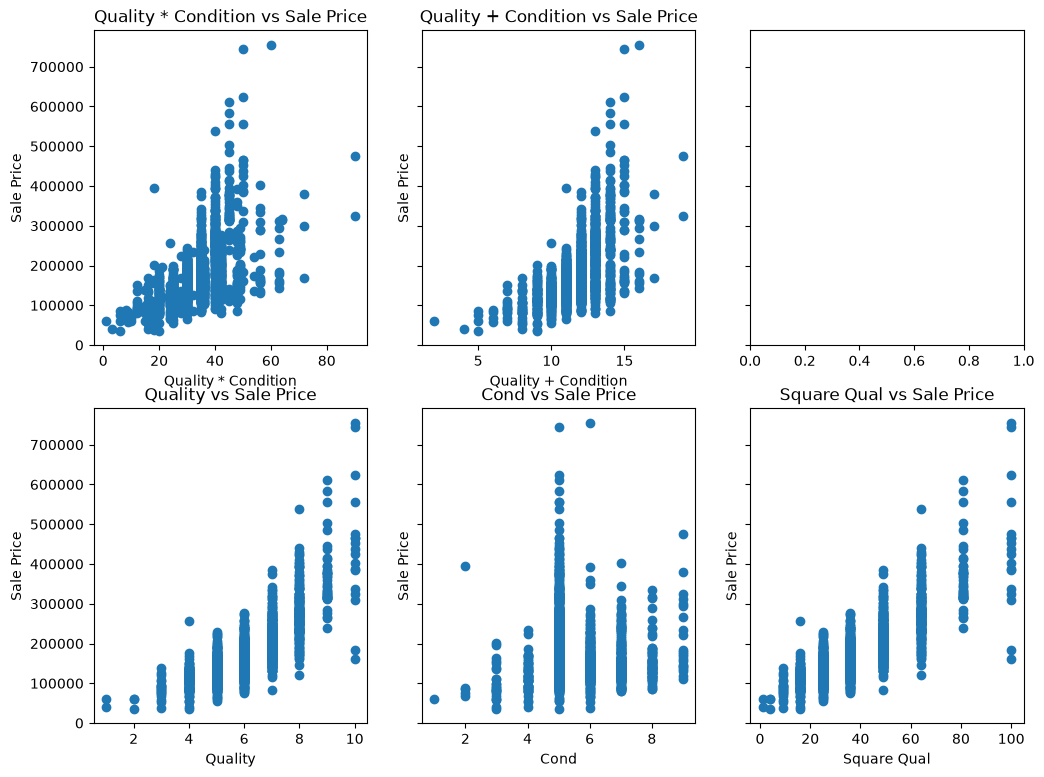

In [33]:
mult_qual_cond = overall_qual * overall_cond
add_qual_cond = overall_qual + overall_cond
square_qual = overall_qual ** 2

fig, axes = plt.subplots(2, 3, figsize=(12,9), sharey=True)

axes[0,0].scatter(mult_qual_cond, sale_price)
axes[0,0].set_title("Quality * Condition vs Sale Price")
axes[0,0].set_xlabel("Quality * Condition")
axes[0,0].set_ylabel("Sale Price")

axes[0,1].scatter(add_qual_cond, sale_price)
axes[0,1].set_title("Quality + Condition vs Sale Price")
axes[0,1].set_xlabel("Quality + Condition")
axes[0,1].set_ylabel("Sale Price")

axes[1,0].scatter(overall_qual, sale_price)
axes[1,0].set_title("Quality vs Sale Price")
axes[1,0].set_xlabel("Quality")
axes[1,0].set_ylabel("Sale Price")

axes[1,1].scatter(overall_cond, sale_price)
axes[1,1].set_title("Cond vs Sale Price")
axes[1,1].set_xlabel("Cond")
axes[1,1].set_ylabel("Sale Price")

axes[1,2].scatter(square_qual, sale_price)
axes[1,2].set_title("Square Qual vs Sale Price")
axes[1,2].set_xlabel("Square Qual")
axes[1,2].set_ylabel("Sale Price")
plt.show()

In [39]:
for p in range(1, 10):
    print((overall_qual ** p).corr(sale_price))

0.7909816005838054
0.8171684436128851
0.825237796790755
0.8190695088085753
0.8014303449283894
0.7753416020391743
0.7439431418382166
0.7100714931835469
0.6759570042978711


In [ ]:
year_built = train_df["YearBuilt"]
year_remodelled = train_df["YearRemodAdd"]
year_sold = train_df["YrSold"]

year_remodelled_arr = year_remodelled.to_numpy()
year_sold_arr = year_sold.to_numpy()

age = year_remodelled_arr - year_sold_arr

In [ ]:
train_matrix = np.array([])
np.hstack(train_matrix, gr_liv_area)
np.hstack(train_matrix, garage_area)
